In [1]:
import os
from scipy.io import loadmat
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import re

In [2]:
import warnings
warnings.filterwarnings('ignore')
pd.options.mode.chained_assignment = None

## Plot SC

In [43]:
df_layers = pd.read_excel('../BWM/SEU_net_wo_corticalLayers.xlsx', header=1, index_col=1)
df_layers = df_layers.iloc[:, 1:]
scaler = MinMaxScaler()
df_scaled = pd.DataFrame(
    scaler.fit_transform(df_layers),
    index=df_layers.index,
    columns=df_layers.columns
)

df_scaled

,FRP,MOp,MOs,SSp-n,SSp-bfd,SSp-ll,SSp-m,SSp-ul,SSp-tr,SSp-un,...,MD,SMT,PVT,RE,CM,RT,PSV,PB,TRN,PRNr
FRP,0.000000,0.000000,0.614604,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000
MOp,0.441167,0.378662,0.534982,0.281224,0.237631,0.211517,0.242158,0.083040,0.402819,0.297850,...,0.000000,0.000000,0.0,0.0,0.0,0.372428,0.0,0.0,0.0,0.720896
MOs,1.000000,0.262542,0.498483,0.202547,0.954544,0.091715,0.286042,0.126060,0.000000,0.000000,...,0.000000,0.208482,0.0,0.0,0.0,0.332571,0.0,0.0,0.0,0.000000
SSp-n,0.000000,0.150043,0.388819,0.542448,0.455849,0.000000,0.460327,0.209069,0.000000,0.358855,...,0.000000,0.000000,0.0,0.0,0.0,0.350530,0.0,0.0,0.0,0.000000
SSp-bfd,0.000000,0.220388,0.232333,0.504613,0.677445,0.048127,0.275838,0.075778,0.872903,0.324635,...,0.000000,0.000000,0.0,0.0,0.0,0.082808,0.0,0.0,0.0,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
RT,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.477782,0.274014,0.0,1.0,0.0,0.329808,0.0,0.0,0.0,0.000000
PSV,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.593837
PB,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,1.000000
TRN,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000


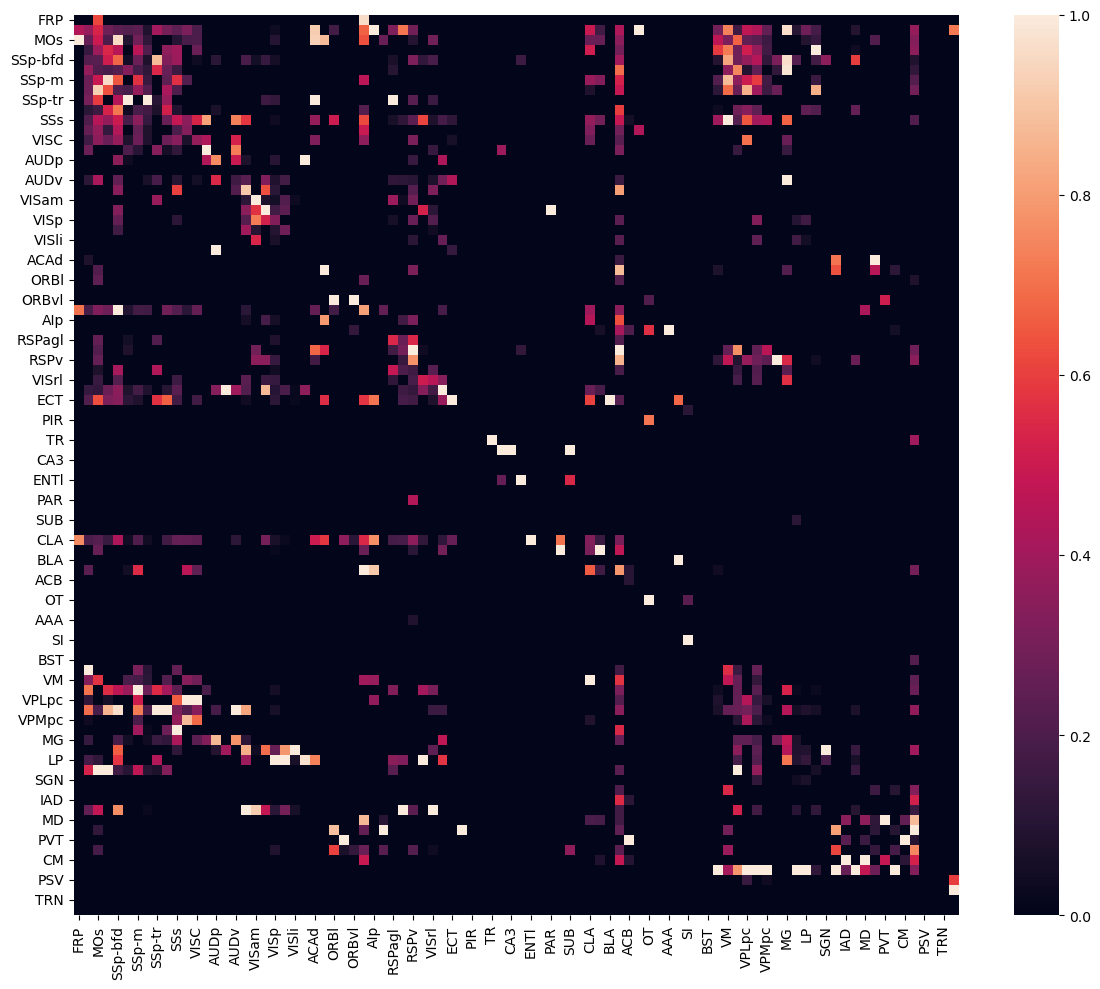

In [50]:
plt.figure(figsize=(12, 10))
sns.heatmap(df_scaled, cmap='rocket', linewidths=0)
plt.title("", fontsize=16)
plt.tight_layout()
plt.savefig("heatmap_wo_layers.pdf", format='pdf', dpi=300, bbox_inches='tight')
plt.show()

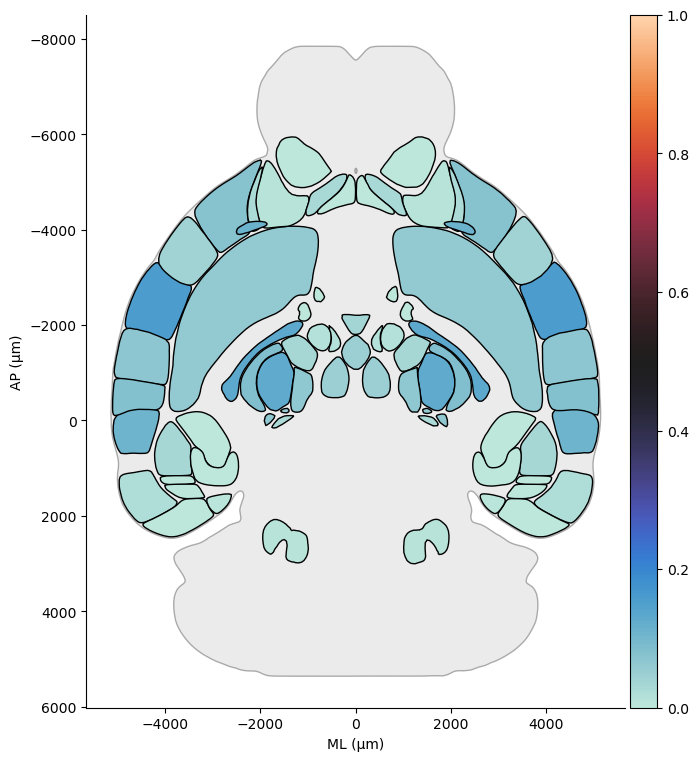

In [54]:
import brainglobe_heatmap as bgh

values = df_scaled.mean(axis=1).to_dict()

# draw brainglobe heatmap
heatmap = bgh.Heatmap(
    values=values,
    position=None,
    orientation="horizontal",
    thickness=1000,
    atlas_name="allen_mouse_25um",
    vmin=0,
    vmax=1,
    cmap="icefire",
    format="2D",
).show(xlabel='ML (μm)', ylabel='AP (μm)')

In [55]:
df_no_layers = pd.read_excel('../BWM/SEU_net_w_corticalLayers.xlsx', header=1, index_col=1)
df_no_layers = df_no_layers.iloc[:, 1:]
scaler = MinMaxScaler()
df_scaled2 = pd.DataFrame(
    scaler.fit_transform(df_no_layers),
    index=df_no_layers.index,
    columns=df_no_layers.columns
)

df_scaled2

,FRP2/3,MOp1,MOp2/3,MOp5,MOp6a,MOs1,MOs2/3,MOs5,MOs6a,SSp-n2/3,...,MD,SMT,PVT,RE,CM,RT,PSV,PB,TRN,PRNr
FRP2/3,0.000000,0.0,0.000000,0.000000,0.000000,0.331930,0.421616,0.600585,0.0,0.000000,...,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000
MOp1,0.000000,0.0,0.157859,0.293038,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,...,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000
MOp2/3,0.413603,0.0,0.228551,0.257367,0.643928,0.284388,0.274564,0.528111,0.0,0.028615,...,0.000000,0.000000,0.0,0.0,0.0,0.403550,0.0,0.0,0.0,0.720896
MOp5,0.000000,0.0,0.117454,0.435530,0.558187,0.162700,0.400272,0.764195,0.0,0.000000,...,0.000000,0.000000,0.0,0.0,0.0,0.343516,0.0,0.0,0.0,0.000000
MOp6a,0.000000,0.0,0.253475,0.059824,0.787805,0.000000,0.000000,0.000000,0.0,0.000000,...,0.000000,0.000000,0.0,0.0,0.0,0.396918,0.0,0.0,0.0,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
RT,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,...,0.477782,0.274014,0.0,1.0,0.0,0.329808,0.0,0.0,0.0,0.000000
PSV,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,...,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.593837
PB,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,...,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,1.000000
TRN,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,...,0.000000,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000


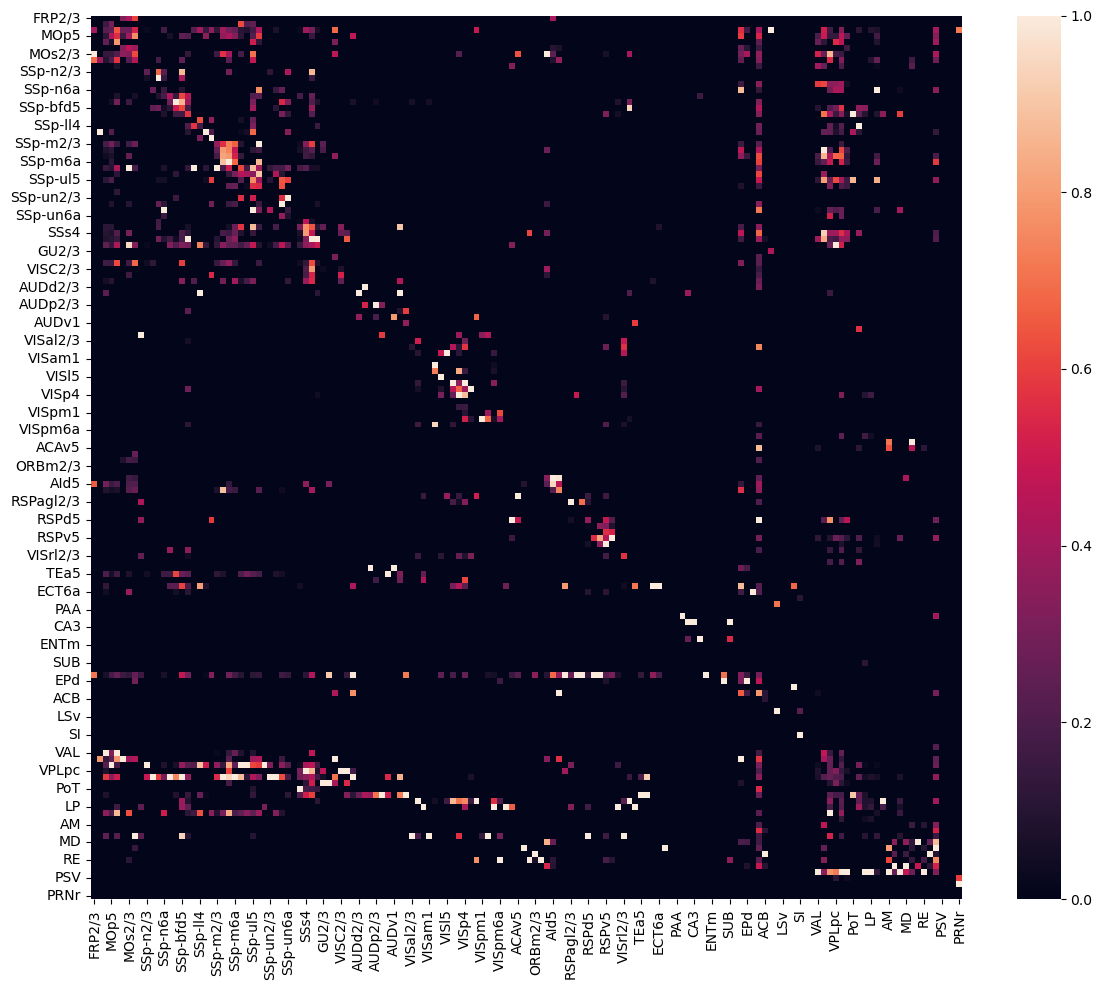

In [60]:
plt.figure(figsize=(12, 10))
sns.heatmap(df_scaled2, cmap='rocket', linewidths=0)
plt.title("", fontsize=16)
plt.tight_layout()
plt.savefig("heatmap_w_layers.pdf", format='pdf', dpi=300, bbox_inches='tight')
plt.show()

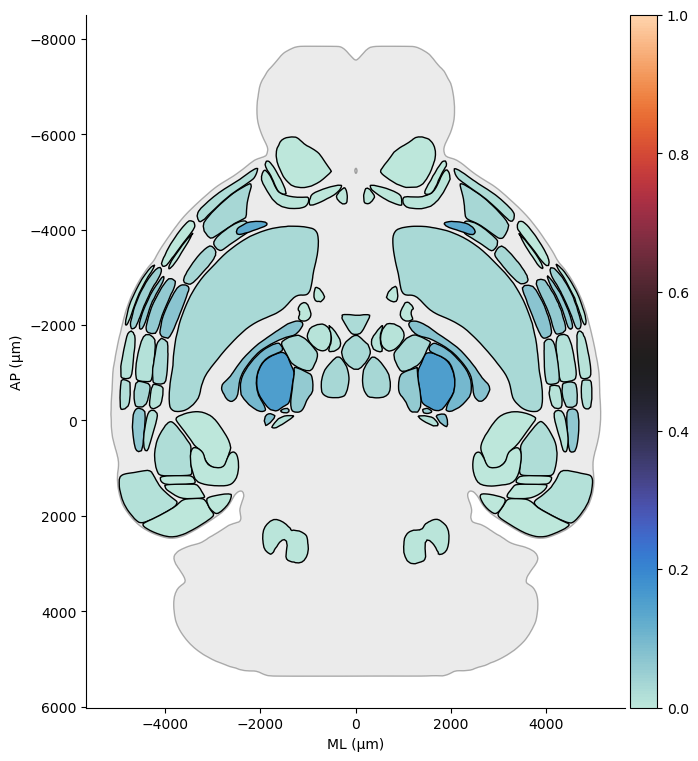

In [61]:
import brainglobe_heatmap as bgh

values = df_scaled2.mean(axis=1).to_dict()

# draw brainglobe heatmap
heatmap = bgh.Heatmap(
    values=values,
    position=None,
    orientation="horizontal",
    thickness=1000,
    atlas_name="allen_mouse_25um",
    vmin=0,
    vmax=1,
    cmap="icefire",
    format="2D",
).show(xlabel='ML (μm)', ylabel='AP (μm)')